In [33]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [30]:
pwd

'/Users/prafulchunchu/Desktop/Duke/AIPI510/moduleProj3/notebooks'

In [31]:
predictive_df = pd.read_csv("../data/raw/ai4i2020.csv")
predictive_df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [8]:
predictive_df.shape

(10000, 14)

In [5]:
predictive_df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
predictive_df.isna().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [7]:
predictive_df.dtypes

UDI                          int64
Product ID                  object
Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

In [17]:
# Checking for duplicated rows

predictive_df.drop(columns=['UDI', 'Product ID']).duplicated().sum()

np.int64(0)

In [10]:
predictive_df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [15]:
product_prefix = predictive_df['Product ID'].str[0]

if predictive_df['Type'].equals(product_prefix):
    print("Exact matching - we can drop Product ID")
else:
    pritn("Not exact matching, look further into the differences between these columns")

Exact matching - we can drop Product ID


In [18]:
# Checking 5 failures against Machine Failure - TWF, HDF, PWF, OSF, and RNF

any_failure_mode = predictive_df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].max(axis=1)

pd.crosstab(any_failure_mode, predictive_df['Machine failure'])

Machine failure,0,1
row_0,,
0,9643,9
1,18,330


In [23]:
# Checking for any correlations between different failures and overall Machine Failure

failure_cols = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
target = 'Machine failure'


for col in failure_cols:
    print(f"--- {col} vs {target} ---")
    display(pd.crosstab(predictive_df[col], predictive_df[target]))

--- TWF vs Machine failure ---


Machine failure,0,1
TWF,,
0,9661,293
1,0,46


--- HDF vs Machine failure ---


Machine failure,0,1
HDF,,
0,9661,224
1,0,115


--- PWF vs Machine failure ---


Machine failure,0,1
PWF,,
0,9661,244
1,0,95


--- OSF vs Machine failure ---


Machine failure,0,1
OSF,,
0,9661,241
1,0,98


--- RNF vs Machine failure ---


Machine failure,0,1
RNF,,
0,9643,338
1,18,1


In [24]:
# We notice that RNF - random failure is 18 when machine didn't fail.  So this could be a bug in how the data was 
# collected or synthesized

In [26]:
predictive_df['any_mode'] = predictive_df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].max(axis=1)
pd.crosstab(predictive_df['any_mode'], predictive_df[target])

Machine failure,0,1
any_mode,,
0,9643,9
1,18,330


In [27]:
# We have 9 machine failures that aren't associated with any of the listed failure types
# I decided to keep the 18 RNF values for failure but doesn't correlate to machine failure and 9 failures not associated
# with any failure types since they are a small percentage of the overall data- hardly 0.08% failure rate. [Insert Math here to show that]

In [41]:
counts = predictive_df[target].value_counts()
percents = predictive_df[target].value_counts(normalize=True) * 100
pd.DataFrame({'count': counts, 'percent': percents.round(2)})

,count,percent
Machine failure,,
0,9661,96.61
1,339,3.39


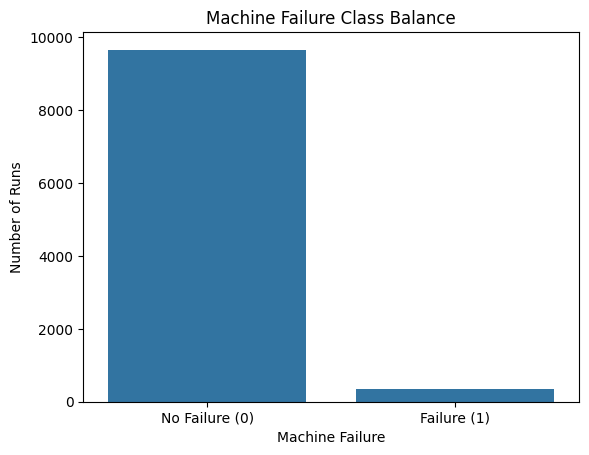

In [42]:
ax = sns.countplot(data=predictive_df, x=target)
ax.set_title('Machine Failure Class Balance')
ax.set_xlabel('Machine Failure')
ax.set_ylabel('Number of Runs')
ax.set_xticks([0, 1])
ax.set_xticklabels(['No Failure (0)', 'Failure (1)'])
plt.show()

Machine failure                           0            1
Air temperature [K]     mean     299.973999   300.886431
                        median   300.000000   301.600000
Process temperature [K] mean     309.995570   310.290265
                        median   310.000000   310.400000
Rotational speed [rpm]  mean    1540.260014  1496.486726
                        median  1507.000000  1365.000000
Torque [Nm]             mean      39.629655    50.168142
                        median    39.900000    53.700000
Tool wear [min]         mean     106.693717   143.781711
                        median   107.000000   165.000000

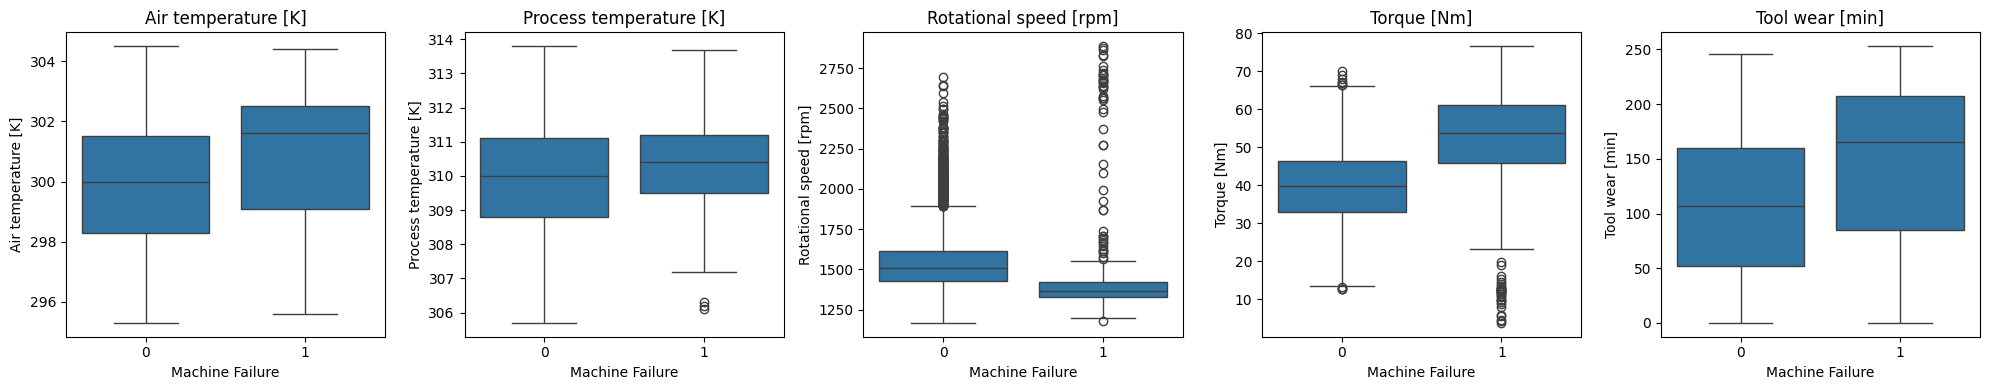

Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64

In [43]:
input_cols = ['Air temperature [K]', 'Process temperature [K]',
              'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

# 1. Average and median of each input, failed vs not failed
display(predictive_df.groupby(target)[input_cols].agg(['mean', 'median']).T)

# 2. Boxplot per input
fig, axes = plt.subplots(1, len(input_cols), figsize=(20, 4))
for ax, col in zip(axes, input_cols):
    sns.boxplot(data=predictive_df, x=target, y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('Machine Failure')
plt.tight_layout()
plt.show()

# 3. Failure rate by product Type
(predictive_df.groupby('Type')[target].mean() * 100).round(2)

In [45]:
# Feature Engineering

predictive_df['temp_diff'] = predictive_df['Process temperature [K]'] - predictive_df['Air temperature [K]']
predictive_df['power'] = predictive_df['Torque [Nm]'] * (predictive_df['Rotational speed [rpm]'] * 2 * np.pi / 60)
predictive_df['strain'] = predictive_df['Tool wear [min]'] * predictive_df['Torque [Nm]']

Machine failure             0            1
temp_diff mean      10.021571     9.403835
          median     9.800000     9.300000
power     mean    6244.547534  7282.819485
          median  6243.046225  7611.429737
strain    mean    4213.842708  7187.938348
          median  3952.800000  7681.800000

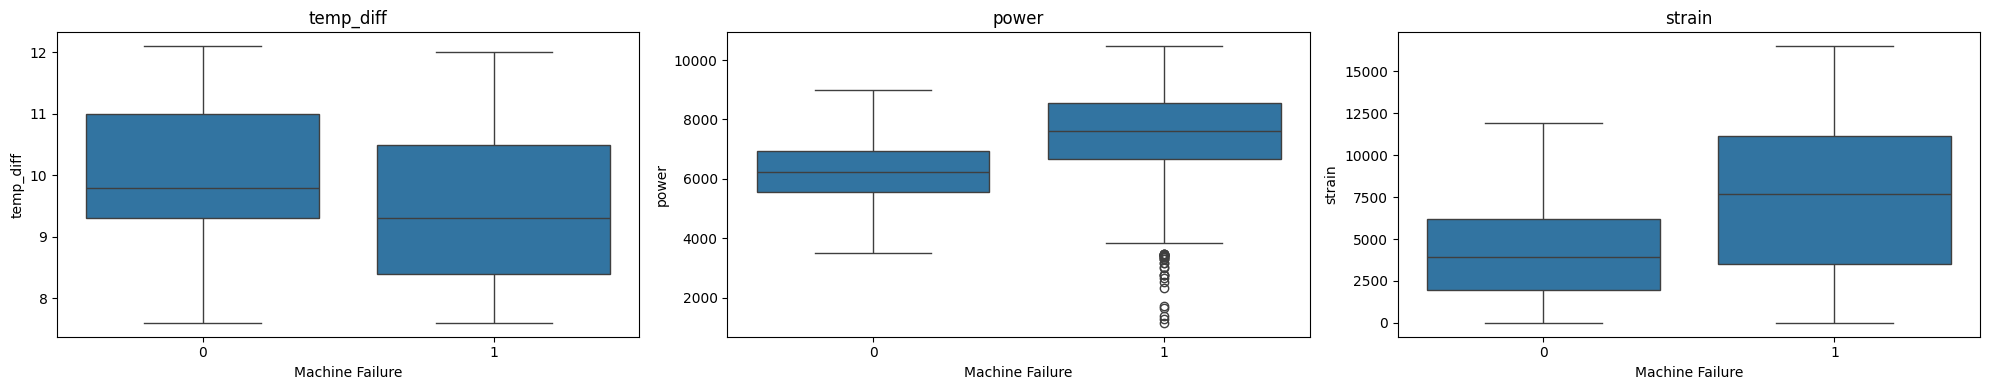

In [46]:
eng_cols = ['temp_diff', 'power', 'strain']

# 1. Average and median of each input, failed vs not failed
display(predictive_df.groupby(target)[eng_cols].agg(['mean', 'median']).T)

# 2. Boxplot per input
fig, axes = plt.subplots(1, len(eng_cols), figsize=(20, 4))
for ax, col in zip(axes, eng_cols):
    sns.boxplot(data=predictive_df, x=target, y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('Machine Failure')
plt.tight_layout()
plt.show()


## 8. Summary

**Data quality**
- 10,000 rows, no missing values, no duplicates (checked after dropping the unique ID columns)
- Product ID's letter matches Type in every row, so Product ID is dropped

**Target**
- Machine failure: 339 failures (3.39%), heavily imbalanced
- A model that always predicts "no failure" scores 96.6% accuracy, so accuracy is misleading
- Primary metric: **F2**, since missed failures cost more than false alarms. Precision, recall, F1 and accuracy also reported

**Leakage**
- TWF, HDF, PWF, OSF, RNF describe why a run failed and are only known after the failure, so they're dropped as inputs

**Failure modes**
- Heat dissipation (HDF) is the largest mode: 115 of 339 failures
- Mode counts add to 355 vs 339 failures, so some failures have two causes
- Label quirks: 18 rows have RNF = 1 but no failure, and 9 failures have no mode. Machine failure is kept as the source of truth

**Inputs vs failure**
- Failures show higher torque and tool wear, and lower speed (with a cluster at very high speed)
- Type L fails most (3.92%) vs H (2.09%), because L has the lowest overstrain limit

**Engineered features** (from the failure rules in the dataset docs)
- `temp_diff` = process temp − air temp -> targets HDF
- `power` = torque × speed in rad/s -> targets PWF. Non failures sit within the 3,500 to 9,000 W safe range
- `strain` = tool wear × torque -> targets OSF. Strongest separator: median nearly doubles for failures